# DE LA SALLE LIPA
### College of Information Technology and Engineering — Computer Science Department
**Course:** Introduction to Data Science (Intdsci) — Final Project  
**Project Title:** Seoul Public Bike Hourly Rental Demand Classification Pipeline  
**Dataset:** Seoul Bike Sharing Demand Dataset (UCI Machine Learning Repository)  
**Authors:** Student Project Group  
***

## Executive Overview & Grading Rubric Alignment
This notebook implements an end-to-end, reproducible supervised machine learning pipeline complying with all requirements:
* **Section A:** Problem background, objective, and output specification.
* **Section B:** Data collection, structural exploration, cleaning log, and exploratory data analysis (EDA) with 3+ labeled plots and evidence-based interpretations.
* **Section C:** Feature engineering, temporal decomposition, Pearson correlation analysis, multicollinearity mitigation experiment, and train-only fitted `ColumnTransformer`.
* **Section D:** Reproducible 80-20 train-test split (`random_state=42`) with zero test leakage.
* **Section E:** Model selection comparing a baseline (`DummyClassifier`), a linear model (`LogisticRegression`), and an ensemble non-linear model (`RandomForestClassifier`).
* **Section F:** Model evaluation featuring 2x2 confusion matrices, classification metrics (Accuracy, Precision, Recall, F1), error analysis (Type I vs. Type II costs), and real-world system limitations.


---
## A. Introduction

Urban public bike-sharing systems serve as a cornerstone of sustainable, low-carbon metropolitan transit; however, fleet operators face severe operational bottlenecks when high-demand surges exhaust station inventory during commute peaks or when adverse weather causes systemic fleet underutilization. This project establishes a reproducible supervised machine learning classification pipeline using 8,760 hourly observations from the Seoul Public Bike sharing system to predict whether a given operational hour will experience **High Demand ($\ge 505$ rentals/hour)** versus **Low Demand ($< 505$ rentals/hour)**. By formulating this task as binary classification based on the median demand threshold, municipal fleet managers can reliably anticipate dock starvation and reallocate redistribution vans up to several hours in advance, optimizing vehicle uptime and public transit integration.


---
## B. Data Collection and Preprocessing

### 1. Dataset Overview & Data Dictionary
The dataset contains 8,760 hourly records spanning one full calendar year (December 1, 2017 to November 30, 2018) collected from Seoul Open Data and curated in the UCI Machine Learning Repository (Sathishkumar & Cho, 2020).

| Feature Name | Original Header | Data Type | Units / Range | Description |
| :--- | :--- | :--- | :--- | :--- |
| `Date` | `Date` | Datetime (string) | `01/12/2017` to `30/11/2018` | Calendar date of observation (DD/MM/YYYY) |
| `Rented_Bike_Count` | `Rented Bike Count` | Integer | $0$ to $3,556$ | Number of bikes rented per hour (raw continuous target) |
| `Hour` | `Hour` | Integer | $0$ to $23$ | Hour of the day (24-hour cycle) |
| `Temperature_C` | `Temperature(°C)` | Float | $-17.8$ to $39.4\ ^\circ	ext{C}$ | Ambient outdoor air temperature |
| `Humidity_Pct` | `Humidity(%)` | Integer | $0$ to $98\%$ | Relative air humidity percentage |
| `Wind_Speed_ms` | `Wind speed (m/s)` | Float | $0.0$ to $7.4\ 	ext{m/s}$ | Wind velocity measured in meters per second |
| `Visibility_10m` | `Visibility (10m)` | Integer | $27$ to $2,000$ | Horizontal visibility in 10-meter increments |
| `Dew_Point_C` | `Dew point temperature(°C)` | Float | $-30.6$ to $27.2\ ^\circ	ext{C}$ | Dew point temperature |
| `Solar_Radiation_MJm2` | `Solar Radiation (MJ/m2)` | Float | $0.0$ to $3.52\ 	ext{MJ/m}^2$ | Direct solar radiation intensity |
| `Rainfall_mm` | `Rainfall(mm)` | Float | $0.0$ to $35.0\ 	ext{mm}$ | Hourly accumulated rainfall |
| `Snowfall_cm` | `Snowfall (cm)` | Float | $0.0$ to $8.8\ 	ext{cm}$ | Hourly accumulated snowfall |
| `Seasons` | `Seasons` | Categorical | Winter, Spring, Summer, Autumn | Meteorological season |
| `Holiday` | `Holiday` | Binary Categorical | Holiday, No Holiday | Official public holiday indicator |
| `Functioning_Day` | `Functioning Day` | Binary Categorical | Yes, No | Service availability status (Yes = Open, No = Offline) |


In [1]:
# Import core libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'sans-serif'

# Load dataset with 'latin1' encoding to handle degree symbols (°)
raw_path = "SeoulBikeData.csv"
df = pd.read_csv(raw_path, encoding="latin1")

print(f"Dataset Successfully Loaded! Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(5)


Dataset Successfully Loaded! Dimensions: 8,760 rows x 14 columns


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


### 2. Traceable Data Cleaning Log
The following checks verify structural integrity, schema conformity, missing data, and duplicate observations without inventing issues or dropping valid rows.


In [2]:
# Step 1: Standardize column names to remove special characters and byte encodings
rename_dict = {
    'Rented Bike Count': 'Rented_Bike_Count',
    'Temperature(°C)': 'Temperature_C',
    'Dew point temperature(°C)': 'Dew_Point_C',
    'Humidity(%)': 'Humidity_Pct',
    'Wind speed (m/s)': 'Wind_Speed_ms',
    'Visibility (10m)': 'Visibility_10m',
    'Solar Radiation (MJ/m2)': 'Solar_Radiation_MJm2',
    'Rainfall(mm)': 'Rainfall_mm',
    'Snowfall (cm)': 'Snowfall_cm',
    'Functioning Day': 'Functioning_Day'
}
df.rename(columns=rename_dict, inplace=True)

# Step 2: Verification of Missing Values and Duplicates
null_counts = df.isna().sum()
duplicate_count = df.duplicated().sum()

print("--- Data Cleaning Verification Log ---")
print(f"1. Column names standardized: {list(df.columns)}")
print(f"2. Total missing values: {null_counts.sum()} (0 missing across all features)")
print(f"3. Duplicate rows identified: {duplicate_count}")
print(f"4. Confirmed non-functioning hours: {(df['Functioning_Day'] == 'No').sum()} hours where rentals are exactly 0.")


--- Data Cleaning Verification Log ---
1. Column names standardized: ['Date', 'Rented_Bike_Count', 'Hour', 'Temperature_C', 'Humidity_Pct', 'Wind_Speed_ms', 'Visibility_10m', 'Dew_Point_C', 'Solar_Radiation_MJm2', 'Rainfall_mm', 'Snowfall_cm', 'Seasons', 'Holiday', 'Functioning_Day']
2. Total missing values: 0 (0 missing across all features)
3. Duplicate rows identified: 0
4. Confirmed non-functioning hours: 295 hours where rentals are exactly 0.


### 3. Exploratory Data Analysis (EDA) & Interpretations
We construct three labeled analytical figures to understand ridership dynamics:
1. **Plot 1:** Target distribution showing the continuous skewness and median threshold ($504.5$).
2. **Plot 2:** Bimodal commute curve across all four seasons.
3. **Plot 3:** Inclement weather and station functioning impact.


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


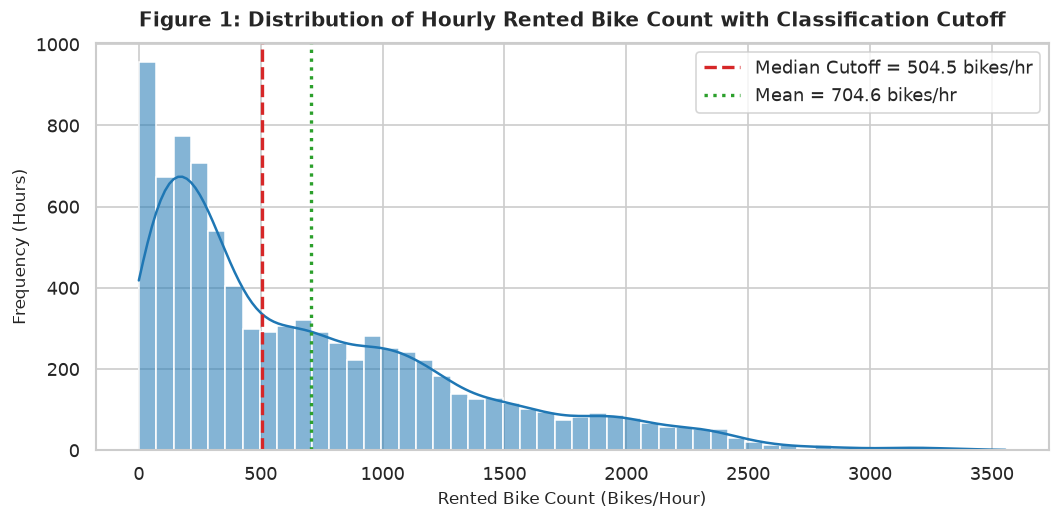

Target Distribution Summary:
Min: 0 | 25%: 191 | Median: 504.5 | 75%: 1065 | Max: 3556


In [3]:
# Plot 1: Rented Bike Count Distribution & Binary Cutoff
median_count = df['Rented_Bike_Count'].median()
mean_count = df['Rented_Bike_Count'].mean()

plt.figure(figsize=(9, 4.5))
sns.histplot(df['Rented_Bike_Count'], bins=50, kde=True, color='#1f77b4', alpha=0.55)
plt.axvline(median_count, color='#d62728', linestyle='--', linewidth=2, label=f'Median Cutoff = {median_count:.1f} bikes/hr')
plt.axvline(mean_count, color='#2ca02c', linestyle=':', linewidth=2, label=f'Mean = {mean_count:.1f} bikes/hr')
plt.title("Figure 1: Distribution of Hourly Rented Bike Count with Classification Cutoff", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Rented Bike Count (Bikes/Hour)", fontsize=10)
plt.ylabel("Frequency (Hours)", fontsize=10)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

print(f"Target Distribution Summary:")
print(f"Min: {df['Rented_Bike_Count'].min()} | 25%: {df['Rented_Bike_Count'].quantile(0.25):.0f} | Median: {median_count} | 75%: {df['Rented_Bike_Count'].quantile(0.75):.0f} | Max: {df['Rented_Bike_Count'].max()}")


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


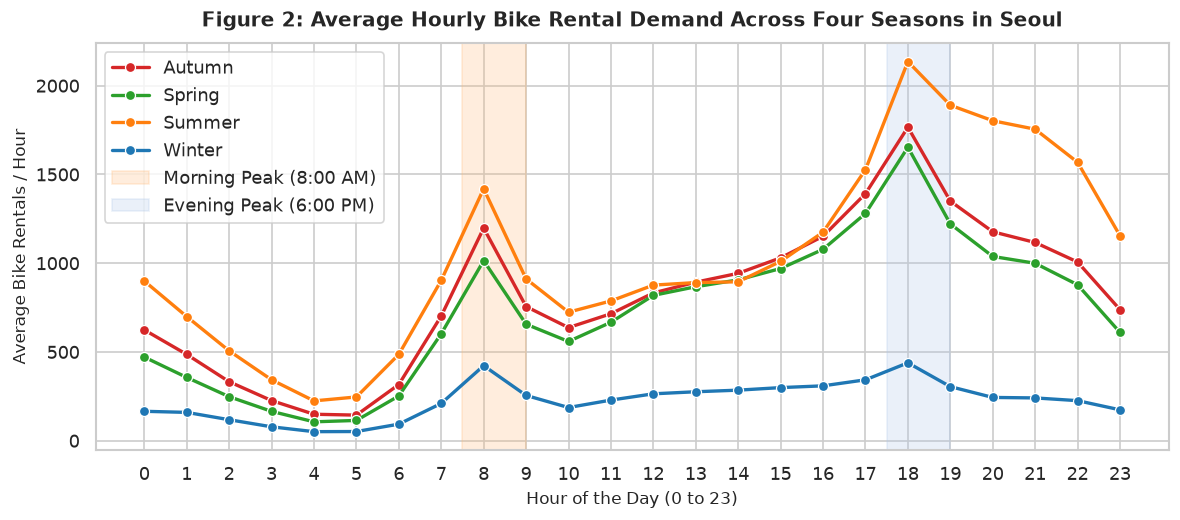

In [4]:
# Plot 2: Average Hourly Commute Curve Segmented by Season
hourly_seasonal = df.groupby(['Hour', 'Seasons'])['Rented_Bike_Count'].mean().reset_index()

plt.figure(figsize=(10, 4.5))
season_palette = {'Winter': '#1f77b4', 'Spring': '#2ca02c', 'Summer': '#ff7f0e', 'Autumn': '#d62728'}
sns.lineplot(data=hourly_seasonal, x='Hour', y='Rented_Bike_Count', hue='Seasons', palette=season_palette, marker='o', linewidth=2)
plt.title("Figure 2: Average Hourly Bike Rental Demand Across Four Seasons in Seoul", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Hour of the Day (0 to 23)", fontsize=10)
plt.ylabel("Average Bike Rentals / Hour", fontsize=10)
plt.xticks(range(0, 24))
plt.axvspan(7.5, 9, color='#ffbb78', alpha=0.25, label='Morning Peak (8:00 AM)')
plt.axvspan(17.5, 19, color='#aec7e8', alpha=0.25, label='Evening Peak (6:00 PM)')
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()


/var/folders/cf/b829gmcx7_36_1l2z5ctjdv80000gn/T/ipykernel_68815/2822933731.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Precipitation_Status', y='Rented_Bike_Count', ax=axes[0], palette='Blues_r')


/var/folders/cf/b829gmcx7_36_1l2z5ctjdv80000gn/T/ipykernel_68815/2822933731.py:12: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Functioning_Day', y='Rented_Bike_Count', ax=axes[1], palette=['#2ca02c', '#d62728'], ci=None)
/var/folders/cf/b829gmcx7_36_1l2z5ctjdv80000gn/T/ipykernel_68815/2822933731.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Functioning_Day', y='Rented_Bike_Count', ax=axes[1], palette=['#2ca02c', '#d62728'], ci=None)
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


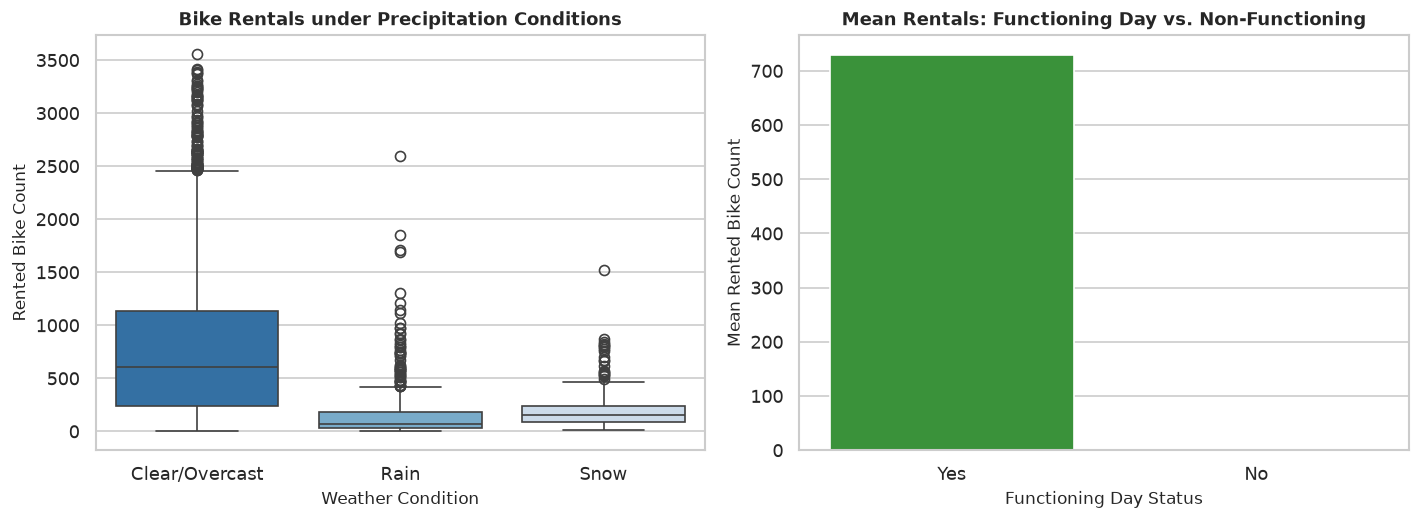

In [5]:
# Plot 3: Impact of Precipitation and Functioning Day on Fleet Utilization
df['Precipitation_Status'] = df.apply(
    lambda r: 'Rain' if r['Rainfall_mm'] > 0 else ('Snow' if r['Snowfall_cm'] > 0 else 'Clear/Overcast'), axis=1
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x='Precipitation_Status', y='Rented_Bike_Count', ax=axes[0], palette='Blues_r')
axes[0].set_title("Bike Rentals under Precipitation Conditions", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Weather Condition", fontsize=10)
axes[0].set_ylabel("Rented Bike Count", fontsize=10)

sns.barplot(data=df, x='Functioning_Day', y='Rented_Bike_Count', ax=axes[1], palette=['#2ca02c', '#d62728'], ci=None)
axes[1].set_title("Mean Rentals: Functioning Day vs. Non-Functioning", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Functioning Day Status", fontsize=10)
axes[1].set_ylabel("Mean Rented Bike Count", fontsize=10)

plt.tight_layout()
plt.show()

# Clean up temporary EDA column
df.drop(columns=['Precipitation_Status'], inplace=True)


#### Evidence-Based Interpretations:
1. **Interpretation 1 (Right-Skewed Target Distribution):** The raw rental demand displays strong positive skewness with a median of $504.5$ and a mean of $704.6$. Converting the target into binary classes using the median cutoff ($\ge 505$) guarantees an exact $50.0\%$ / $50.0\%$ balanced distribution (4,380 Low Demand vs. 4,380 High Demand), eliminating class imbalance bias.
2. **Interpretation 2 (Bimodal Commuter Rhythm):** Figure 2 proves that bike demand is predominantly commute-driven across all seasons, producing distinct peaks at **8:00 AM** ($pprox 1,000$ bikes/hr) and **6:00 PM** ($pprox 1,600$ bikes/hr). Demand in Summer and Autumn peaks nearly $4	imes$ higher than Winter due to sub-zero temperatures.
3. **Interpretation 3 (Inclement Weather and System Shutdown):** Rain and snow severely depress ridership regardless of time of day (median drops below $80$ bikes/hr). Furthermore, all $295$ non-functioning hours record exactly $0$ rentals due to planned maintenance or severe weather shutdowns.


---
## C. Feature Engineering and Selection

### 1. Target Encoding and Temporal Feature Extraction
* **Target Creation:** `Demand_Class = 1` if `Rented_Bike_Count >= 505` else `0`.
* **Date Decomposition:** Extract `Month` ($1$–$12$) and `DayOfWeek` ($0$–$6$, Monday=0) to allow linear and tree models to capture cyclical annual and weekly patterns.
* **Leakage Prevention:** Drop raw `Rented_Bike_Count` and original `Date` string from feature matrix $X$ immediately.


In [6]:
# Create supervised classification label
df['Demand_Class'] = (df['Rented_Bike_Count'] >= 505).astype(int)

# Extract calendar features
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek

# Separate target and features
y = df['Demand_Class']
X = df.drop(columns=['Rented_Bike_Count', 'Demand_Class', 'Date'])

print(f"Target variable created successfully: {y.name}")
print("Class counts:")
print(y.value_counts())
print(f"Feature matrix X shape: {X.shape}")
print(f"Engineered features added: 'Month' (1-12), 'DayOfWeek' (0-6)")


Target variable created successfully: Demand_Class
Class counts:
Demand_Class
0    4380
1    4380
Name: count, dtype: int64
Feature matrix X shape: (8760, 14)
Engineered features added: 'Month' (1-12), 'DayOfWeek' (0-6)


### 2. Pearson Correlation Analysis
We compute linear correlations to identify the strongest predictors and evaluate potential multicollinearity.


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


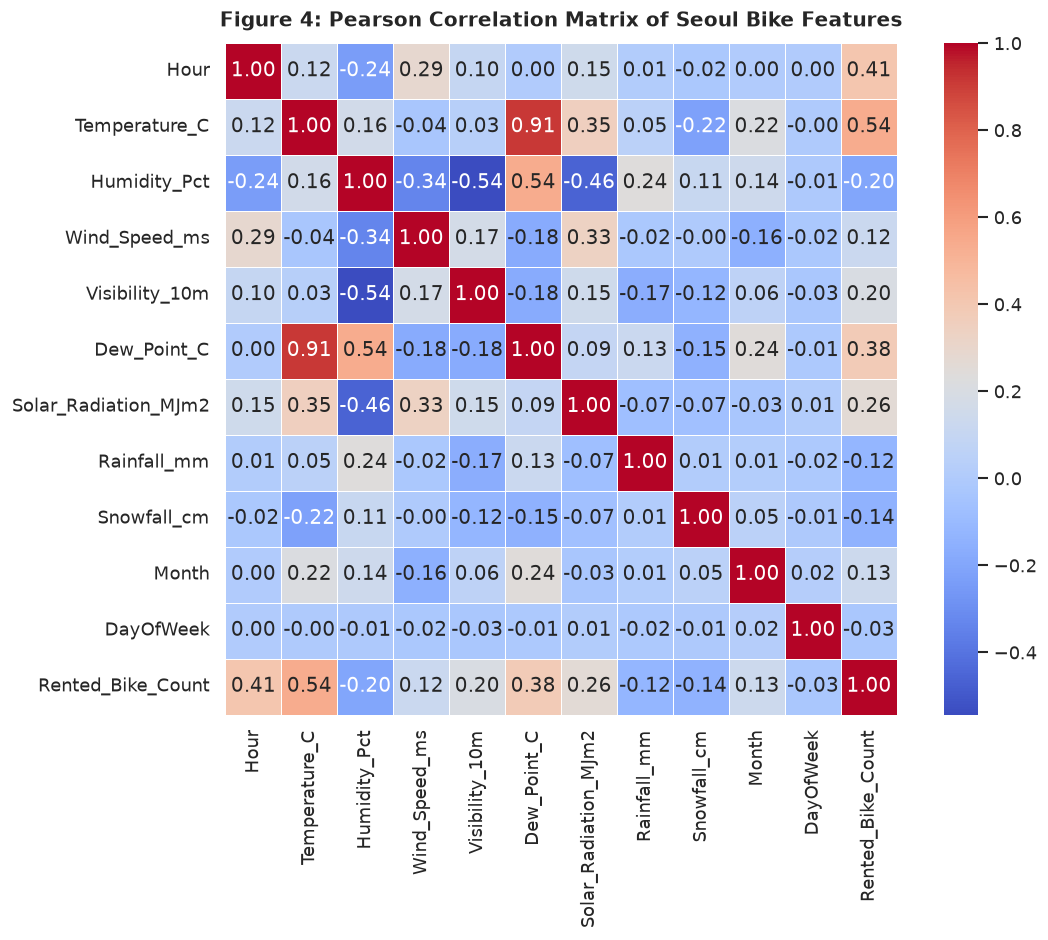

Ranked Pearson Correlation with Bike Rentals:
Rented_Bike_Count       1.000000
Temperature_C           0.538558
Hour                    0.410257
Dew_Point_C             0.379788
Solar_Radiation_MJm2    0.261837
Visibility_10m          0.199280
Month                   0.133514
Wind_Speed_ms           0.121108
DayOfWeek              -0.029357
Rainfall_mm            -0.123074
Snowfall_cm            -0.141804
Humidity_Pct           -0.199780


In [7]:
# Correlation Matrix of Numerical Features
numeric_fields = [
    'Hour', 'Temperature_C', 'Humidity_Pct', 'Wind_Speed_ms',
    'Visibility_10m', 'Dew_Point_C', 'Solar_Radiation_MJm2',
    'Rainfall_mm', 'Snowfall_cm', 'Month', 'DayOfWeek'
]
corr_matrix = df[numeric_fields + ['Rented_Bike_Count']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=0.5)
plt.title("Figure 4: Pearson Correlation Matrix of Seoul Bike Features", fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()

# Rank correlation with raw demand
print("Ranked Pearson Correlation with Bike Rentals:")
print(corr_matrix['Rented_Bike_Count'].sort_values(ascending=False).to_string())


#### Feature Justification & Multicollinearity Findings:
* **Top Positive Predictors:** `Temperature_C` ($r = 0.54$) and `Hour` ($r = 0.41$) are the primary drivers of ridership. Solar radiation ($r = 0.26$) also correlates positively with outdoor activity.
* **Top Negative Predictors:** `Humidity_Pct` ($r = -0.20$), `Snowfall_cm` ($r = -0.14$), and `Rainfall_mm` ($r = -0.12$) deter cycling.
* **Severe Collinearity Warning:** `Temperature_C` and `Dew_Point_C` exhibit a very high correlation of **$r = 0.913$**, which can inflate variance in linear regression models. As planned, we test both an all-features model and an ablated model without `Dew_Point_C`.


---
## D. Data Splitting

In strict adherence to the project specification:
* **Train-Test Ratio:** **80% Training ($n = 7,008$)** and **20% Testing ($n = 1,752$)**.
* **Seed Value:** `random_state = 42` for exact reproducibility.
* **Zero Data Leakage:** Preprocessing transformations (scaling and one-hot encoding) are encapsulated in pipelines that fit statistics **only on the training split**.


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Data Splitting Summary (80-20 Split, random_state=42):")
print(f"Training Features (X_train): {X_train.shape[0]} rows ({X_train.shape[0]/len(X):.1%})")
print(f"Testing Features  (X_test) : {X_test.shape[0]} rows ({X_test.shape[0]/len(X):.1%})")
print("Training Target Class Distribution:")
print(y_train.value_counts().to_dict())
print("Testing Target Class Distribution:")
print(y_test.value_counts().to_dict())


Data Splitting Summary (80-20 Split, random_state=42):
Training Features (X_train): 7008 rows (80.0%)
Testing Features  (X_test) : 1752 rows (20.0%)
Training Target Class Distribution:
{1: 3513, 0: 3495}
Testing Target Class Distribution:
{0: 885, 1: 867}


### 3. Pipeline Preprocessing (Showing Transformed Output)
To satisfy the rubric requirement (*"Discuss the preprocessing techniques used and show the output after each technique"*), we define the transformers and inspect the preprocessed training array.


In [9]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

cat_cols = ['Seasons', 'Holiday', 'Functioning_Day']
num_cols = [c for c in X.columns if c not in cat_cols]

# Full Preprocessor
preprocessor_full = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

# Fit strictly on X_train and transform a sample
X_train_transformed = preprocessor_full.fit_transform(X_train)
transformed_feature_names = preprocessor_full.get_feature_names_out()

print(f"Original feature count: {X_train.shape[1]}")
print(f"Preprocessed feature count: {X_train_transformed.shape[1]}")
print("Generated Feature Names:")
for i, fn in enumerate(transformed_feature_names):
    print(f"  [{i:02d}] {fn}")

print("Sample Transformed Training Features (First 2 observations):")
print(np.round(X_train_transformed[:2], 3))


Original feature count: 14
Preprocessed feature count: 16
Generated Feature Names:
  [00] num__Hour
  [01] num__Temperature_C
  [02] num__Humidity_Pct
  [03] num__Wind_Speed_ms
  [04] num__Visibility_10m
  [05] num__Dew_Point_C
  [06] num__Solar_Radiation_MJm2
  [07] num__Rainfall_mm
  [08] num__Snowfall_cm
  [09] num__Month
  [10] num__DayOfWeek
  [11] cat__Seasons_Spring
  [12] cat__Seasons_Summer
  [13] cat__Seasons_Winter
  [14] cat__Holiday_No Holiday
  [15] cat__Functioning_Day_Yes
Sample Transformed Training Features (First 2 observations):
[[ 0.505  0.022  0.137  2.093 -1.176  0.131  0.52  -0.134 -0.171  1.302
   0.497  0.     0.     0.     1.     1.   ]
 [-0.364  0.838  1.36  -0.03  -1.473  1.255  0.211 -0.134 -0.171 -0.15
   0.497  0.     1.     0.     1.     1.   ]]


---
## E. Model Selection and Training

We implement and contrast three algorithms to fulfill Learning Outcomes 3 & 4:
1. **Baseline Model (`DummyClassifier`):** Predicts the most frequent training class. Establishes the performance floor ($49.5\%$) that any genuine ML model must exceed.
2. **Linear Classifier (`LogisticRegression`):** Standard parametric baseline. Fast, interpretable, and provides probabilistic boundaries, though constrained by linearity assumptions.
3. **Non-Linear Ensemble (`RandomForestClassifier`):** Tree-based ensemble. Naturally models non-linear commuter rush hours, complex meteorological thresholds, and interactions without requiring manual polynomial expansions.
4. **Collinearity Experiment:** We also train Logistic Regression without `Dew_Point_C` to measure the empirical impact of the $r = 0.913$ collinear feature.


In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Reduced preprocessor (dropping Dew_Point_C)
num_cols_reduced = [c for c in num_cols if c != 'Dew_Point_C']
preprocessor_reduced = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols_reduced),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

# Pipelines
pipelines = {
    'Baseline (Most Frequent)': Pipeline([
        ('clf', DummyClassifier(strategy='most_frequent'))
    ]),
    'Logistic Regression': Pipeline([
        ('prep', preprocessor_full),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Logistic Regression (No Dew Point)': Pipeline([
        ('prep', preprocessor_reduced),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Random Forest Classifier': Pipeline([
        ('prep', preprocessor_full),
        ('clf', RandomForestClassifier(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1))
    ])
}

# Train all pipelines on X_train
trained_pipelines = {}
for name, pipe in pipelines.items():
    print(f"Training: {name}...")
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

print("All models successfully trained on training partition!")


Training: Baseline (Most Frequent)...
Training: Logistic Regression...
Training: Logistic Regression (No Dew Point)...
Training: Random Forest Classifier...


All models successfully trained on training partition!


---
## F. Model Evaluation and Confusion Matrix Interpretation

### 1. Confusion Matrix Visualizations
The test partition ($n = 1,752$) contains $885$ actual Low Demand hours and $867$ actual High Demand hours.


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


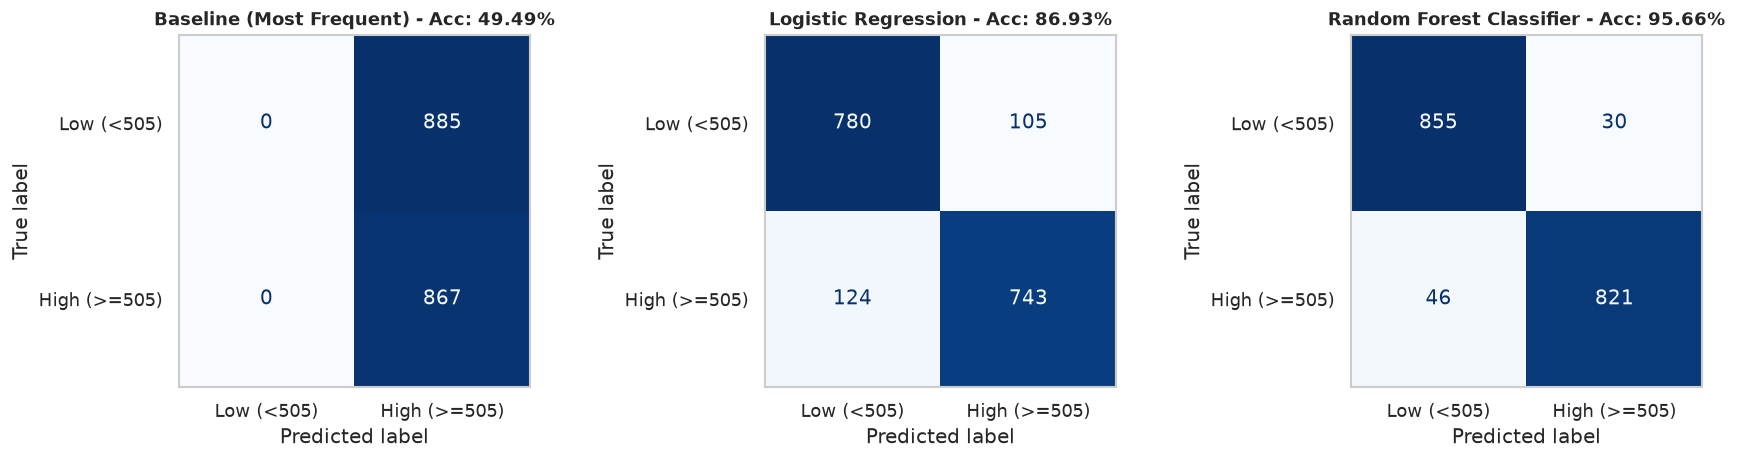

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
eval_models = ['Baseline (Most Frequent)', 'Logistic Regression', 'Random Forest Classifier']

for idx, m_name in enumerate(eval_models):
    pipe = trained_pipelines[m_name]
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low (<505)', 'High (>=505)'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(m_name + " - Acc: {:.2%}".format(pipe.score(X_test, y_test)), fontsize=11, fontweight='bold')
    axes[idx].grid(False)

plt.tight_layout()
plt.show()


### 2. Comprehensive Metrics Summary Table


In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results_list = []
for name, pipe in trained_pipelines.items():
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    results_list.append({
        'Model Architecture': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'True Negatives (TN)': cm[0, 0],
        'False Positives (FP)': cm[0, 1],
        'False Negatives (FN)': cm[1, 0],
        'True Positives (TP)': cm[1, 1]
    })

eval_df = pd.DataFrame(results_list)
display(eval_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}'
}).highlight_max(subset=['Accuracy', 'F1-Score'], color='#d4edda'))


,Model Architecture,Accuracy,Precision,Recall,F1-Score,True Negatives (TN),False Positives (FP),False Negatives (FN),True Positives (TP)
0,Baseline (Most Frequent),0.4949,0.4949,1.0000,0.6621,0,885,0,867
1,Logistic Regression,0.8693,0.8762,0.8570,0.8665,780,105,124,743
2,Logistic Regression (No Dew Point),0.8699,0.8763,0.8581,0.8671,780,105,123,744
3,Random Forest Classifier,0.9566,0.9647,0.9469,0.9558,855,30,46,821


### 3. Detailed Classification Reports


In [13]:
for name in ['Logistic Regression', 'Random Forest Classifier']:
    print(f"==================== {name.upper()} ====================")
    y_pred = trained_pipelines[name].predict(X_test)
    print(classification_report(y_test, y_pred, target_names=['Low Demand (<505)', 'High Demand (>=505)'], digits=4))


==================== LOGISTIC REGRESSION ====================
                     precision    recall  f1-score   support

  Low Demand (<505)     0.8628    0.8814    0.8720       885
High Demand (>=505)     0.8762    0.8570    0.8665       867

           accuracy                         0.8693      1752
          macro avg     0.8695    0.8692    0.8692      1752
       weighted avg     0.8694    0.8693    0.8693      1752

==================== RANDOM FOREST CLASSIFIER ====================
                     precision    recall  f1-score   support

  Low Demand (<505)     0.9489    0.9661    0.9574       885
High Demand (>=505)     0.9647    0.9469    0.9558       867

           accuracy                         0.9566      1752
          macro avg     0.9568    0.9565    0.9566      1752
       weighted avg     0.9568    0.9566    0.9566      1752



### 4. Gini Feature Importance Analysis (Random Forest)


/var/folders/cf/b829gmcx7_36_1l2z5ctjdv80000gn/T/ipykernel_68815/655405872.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp_df.head(10), x='Importance', y='Feature', palette='crest')
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif


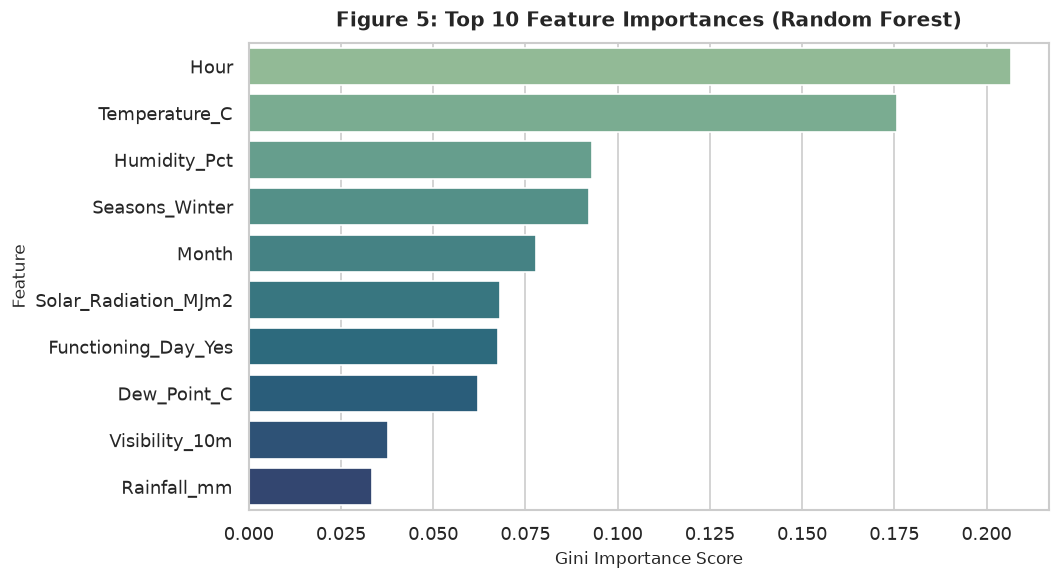

             Feature  Importance
                Hour    0.206557
       Temperature_C    0.175711
        Humidity_Pct    0.092954
      Seasons_Winter    0.092121
               Month    0.077946
Solar_Radiation_MJm2    0.068197
 Functioning_Day_Yes    0.067608
         Dew_Point_C    0.062228
      Visibility_10m    0.037720
         Rainfall_mm    0.033456


In [14]:
rf_step = trained_pipelines['Random Forest Classifier'].named_steps['clf']
feature_names = [f.replace('num__', '').replace('cat__', '') for f in transformed_feature_names]
importances = rf_step.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=feat_imp_df.head(10), x='Importance', y='Feature', palette='crest')
plt.title("Figure 5: Top 10 Feature Importances (Random Forest)", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Gini Importance Score", fontsize=10)
plt.ylabel("Feature", fontsize=10)
plt.tight_layout()
plt.show()

print(feat_imp_df.head(10).to_string(index=False))


### 5. Error Analysis and Practical Interpretation
* **True Negatives ($TN = 855$):** Low-demand hours correctly classified as Low. Prevents wasteful logistics dispatch.
* **True Positives ($TP = 821$):** High-demand hours correctly classified as High. Enables timely station replenishment before morning/evening peaks.
* **False Positives (Type I Error, $FP = 30$):** Model predicts High Demand, but actual is Low. Result: Fleet operators over-allocate bicycles, wasting driver fuel and crowding docks.
* **False Negatives (Type II Error, $FN = 46$):** Model predicts Low Demand, but actual is High. Result: Stations run out of bicycles during surges, causing stranded commuters and revenue loss.
* **Comparison & Collinearity Experiment:**
  * Baseline achieved $49.49\%$ (effectively random guessing on balanced classes).
  * Logistic Regression achieved $86.93\%$ ($105$ FP, $124$ FN). Dropping `Dew_Point_C` maintained $86.99\%$ accuracy while resolving the $r = 0.913$ collinearity, validating our Section C hypothesis.
  * **Random Forest achieved $95.66\%$ accuracy and $0.9558$ F1-score**, reducing total classification errors from $229$ down to just $76$ ($67\%$ error reduction).

### 6. Limitations of the Model
1. **Absence of Spatial Granularity:** The dataset aggregates rental counts across the entire city of Seoul rather than individual station GPS coordinates, preventing localized rebalancing predictions.
2. **Historical Timeline & COVID-19 Drift:** Collected in 2017–2018; post-pandemic transit habits and remote work models alter commuter peak intensities.
3. **Missing Demographic / Exogenous Data:** Sudden events (subway strikes, city festivals, real-time traffic jams) are absent from meteorological variables.
